# Viability

> Can selling part of the readjusted land pay for the tunnel?

Readjustment replans the land around the portal at higher density. The new homes make the land more valuable, and a
share of it, the reserve, is sold to pay for the tunnel. The owners keep the rest. So we need the tunnel's cost, the
value of the new land, and a way to compare money spent and received in different years. The cost comes from
notebook 05.


In [ ]:
import itertools

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from fastcore.test import test_close, test_eq

from tunnel.config import (
    BNG,
    COLOURS,
    DERIVED,
    FIGURES,
    PRICE_YEAR,
    catchment,
    use_style,
)
from tunnel.data import OA_BOUNDARIES, households, land_values, ons_layer, real
from tunnel.ownership import constraints, rotherhithe_side

use_style()

## Money over time

£1 in $t$ years is worth $(1+r)^{-t}$ today at discount rate $r$. The Treasury's Green Book uses 3.5%; a developer
would want more like 7%.


In [ ]:
RATES = {"3.5% (Green Book)": 0.035, "7% (commercial)": 0.07}


def discount(t, r):
    "What £1 in `t` years is worth today at rate `r`."
    return (1 + r) ** -np.asarray(t, dtype=float)

In [ ]:
test_eq(discount(0, 0.035), 1)
test_close(discount(20, 0.035), 0.503, eps=1e-3)  # money halves in about 20 years

Spending spread evenly over several years is worth the average of their discount factors.


In [ ]:
def pv_spread(amount, years, r):
    "Present value of `amount` spent in equal parts over `years`."
    return amount * discount(years, r).mean()

In [ ]:
test_close(pv_spread(100, [2, 3], 0.1), 100 * (1.1**-2 + 1.1**-3) / 2)

Land sales follow the building. If `per_year` homes are completed each year from `first`, and each tranche of land
sells `lead` years before its homes are finished, the receipts are worth the home-weighted average discount factor.


In [ ]:
FIRST_COMPLETIONS_YEAR = 6  # masterplan, vote and planning, then build, alongside the tunnel
LAND_SALE_LEAD_YEARS = 2
DELIVERY_PER_YEAR = 500


def build_out_factor(homes, r, per_year=DELIVERY_PER_YEAR, first=FIRST_COMPLETIONS_YEAR, lead=LAND_SALE_LEAD_YEARS):
    "Average discount factor on receipts from building `homes` at `per_year`."
    if homes <= 0:
        return 1.0
    full, part = divmod(homes, per_year)
    tranches = np.array([per_year] * int(full) + ([part] if part else []))
    return float((tranches * discount(first - lead + np.arange(len(tranches)), r)).sum() / homes)

In [ ]:
test_close(build_out_factor(500, 0.1), 1.1**-4)  # one year's worth, sold in year 4
test_close(build_out_factor(750, 0.1), (500 * 1.1**-4 + 250 * 1.1**-5) / 750)

## 1 · What the tunnel costs

Notebook 05 prices the immersed tube with ramps item by item (its estimate D):


In [ ]:
COST = pd.read_csv(DERIVED / "tunnel_cost.csv", index_col=0).loc["working estimate"]
COST.round(0)

low        131.0
central    203.0
high       370.0
Name: working estimate, dtype: float64

Spending starts after two years of design and consents and runs for four.


In [ ]:
CONSTRUCTION_YEARS = [2, 3, 4, 5]
pv_cost = {rate: {k: pv_spread(v, CONSTRUCTION_YEARS, r) for k, v in COST.items()} for rate, r in RATES.items()}
pd.DataFrame(pv_cost).T.round(0)

,low,central,high
3.5% (Green Book),116.0,180.0,328.0
7% (commercial),103.0,161.0,293.0


## 2 · What it adds to existing homes

From notebook 04:


In [ ]:
oa_uplift = pd.read_csv(DERIVED / "oa_uplift.csv")
existing = oa_uplift.uplift_gbp_Central.sum() / 1e6
f"£{existing:.0f}m, {existing / COST['central']:.0%} of the cost"

'£29m, 14% of the cost'

Not enough, even if it could all be taxed. The new homes are where the money is.

## 3 · What the new land is worth

### How much land

The readjustment area is the same as in notebook 02. Output areas are clipped to it, with their Census households
shared out by area, and parks, water, schools and places of worship taken out.


In [ ]:
side = rotherhithe_side(catchment())
oa = ons_layer(OA_BOUNDARIES).to_crs(BNG)[["OA21CD", "geometry"]].merge(households(), on="OA21CD")
area = gpd.clip(oa.assign(oa_area=oa.area), side)
area["households"] = area.households * area.area / area.oa_area
area["geometry"] = area.geometry.difference(constraints(side).union_all())
DEV_HA = area.area.sum() / 1e4
EXISTING_DPH = area.households.sum() / DEV_HA
f"{DEV_HA:.1f} ha developable, {area.households.sum():,.0f} households, {EXISTING_DPH:.0f} per ha"

'52.1 ha developable, 3,261 households, 63 per ha'

### How much each new home's land is worth

MHCLG values Southwark's residential land at its "high density" assumption of 260 homes/ha, at the median house
price. Divided by 260, that's the land value per home. We keep the same value per home at 400/ha: taller buildings
cost more per home to build, which roughly offsets having more of them.


In [ ]:
southwark = land_values().loc["Southwark"]
LAND_PER_HOME = real(southwark.high_50 / southwark.dph_high, 2023)
f"£{LAND_PER_HOME:,.0f} per home"

'£263,616 per home'

New homes near the portal would also be worth more because of the tunnel. To keep the figures conservative we leave
that out of the main case. As a sensitivity we add notebook 04's high-case uplift, averaged over the developable
land, on the price of a typical new-build flat in SE16.


In [ ]:
sales = pd.read_csv(DERIVED / "sales.csv")
new_flats = sales.query("district == 'SE16' and new_build == 'Y' and property_type == 'F' and year >= 2021")
NEW_HOME_PRICE = new_flats.price.median()
ha = (area.area / 1e4).set_axis(area.OA21CD)
pct = oa_uplift.set_index("OA21CD").reindex(ha.index)
high = pct.uplift_pct_High
premium = {"none": 0.0, "high": float((high * ha).sum() / ha[high.notna()].sum())}
f"£{NEW_HOME_PRICE:,.0f} new-build flat (n={len(new_flats)}), high-case premium {premium['high']:.1%}"

'£610,000 new-build flat (n=115), high-case premium 21.9%'

### One scenario

Rebuild `share` of the developable land at `target` homes/ha. The homes standing there now are knocked down and
replaced; the rest are new. The new homes' land is the prize. `reserve` of it is sold to fund the tunnel, and the
owners keep the rest but must pay to rebuild their own homes.


In [ ]:
BUILD_COST_PER_HOME = 340_000  # about 85 m² at £4,000/m², all-in


def scenario(share, target, land_per_home, reserve, dev_ha=DEV_HA, existing_dph=EXISTING_DPH):
    "Homes and land values (nominal £) from rebuilding `share` of the land at `target` homes/ha."
    rebuilt_ha = dev_ha * share
    replaced = rebuilt_ha * existing_dph
    new = rebuilt_ha * max(target - existing_dph, 0)
    land = new * land_per_home
    rebuild = replaced * BUILD_COST_PER_HOME
    return {
        "replaced": replaced,
        "new": new,
        "land": land,
        "reserve": reserve * land,
        "rebuild": rebuild,
        "owners": (1 - reserve) * land - rebuild,
    }

In [ ]:
toy = scenario(share=0.5, target=250, land_per_home=100_000, reserve=0.4, dev_ha=10, existing_dph=50)
test_eq(toy, {"replaced": 250, "new": 1000, "land": 100e6, "reserve": 40e6, "rebuild": 85e6, "owners": 60e6 - 85e6})

In the toy, density is too low to pay for rebuilding: the owners would lose £25m. That's the trade-off we need to
explore.

### Every scenario

We try a few redevelopment shares, the two MHCLG high densities (260/ha for Southwark, 400/ha across the river in
Tower Hamlets) and reserves of 30% and 40%. Everything is then discounted over the build-out.


In [ ]:
SHARES, TARGETS, RESERVES = [0.20, 0.35, 0.50], [260, 400], [0.30, 0.40]
rows = []
for share, target, case, reserve in itertools.product(SHARES, TARGETS, premium, RESERVES):
    s = scenario(share, target, LAND_PER_HOME + premium[case] * NEW_HOME_PRICE, reserve)
    row = {
        "share": share,
        "target": target,
        "premium": case,
        "reserve_share": reserve,
        "years": np.ceil(s["new"] / DELIVERY_PER_YEAR),
    }
    row |= {k: v / 1e6 if k in ("land", "reserve", "rebuild", "owners") else v for k, v in s.items()}
    for rate, r in RATES.items():
        f = build_out_factor(s["new"], r)
        row |= {f"{k} PV {rate}": row[k] * f for k in ("land", "reserve", "rebuild", "owners")}
    rows.append(row)
scen = pd.DataFrame(rows)
scen.to_csv(DERIVED / "development_scenarios.csv", index=False)
central = scen[scen.premium == "none"]
central.pivot_table(
    index=["share", "target", "years"], columns="reserve_share", values=[f"reserve PV {r}" for r in RATES]
).round(0)

reserve PV 3.5% (Green Book)         \
reserve_share                               0.3    0.4   
share target years                                       
0.20  260    5.0                          134.0  179.0   
      400    8.0                          219.0  292.0   
0.35  260    8.0                          223.0  298.0   
      400    13.0                         351.0  469.0   
0.50  260    11.0                         303.0  405.0   
      400    18.0                         462.0  616.0   

                   reserve PV 7% (commercial)         
reserve_share                             0.3    0.4  
share target years                                    
0.20  260    5.0                        112.0  149.0  
      400    8.0                        174.0  233.0  
0.35  260    8.0                        178.0  237.0  
      400    13.0                       260.0  347.0  
0.50  260    11.0                       231.0  308.0  
      400    18.0                       321.0  427.0

How much of the tunnel each would pay for, both sides in present values:


In [ ]:
pd.concat(
    {rate: central.pivot_table(index=["share", "target"], columns="reserve_share", values=f"reserve PV {rate}") / pv_cost[rate]["central"] for rate in RATES},
    axis=1,
).map("{:.0%}".format)  # fmt: skip

3.5% (Green Book)       7% (commercial)      
reserve_share               0.3   0.4             0.3   0.4
share target                                               
0.20  260                   75%   99%             70%   93%
      400                  122%  162%            109%  145%
0.35  260                  124%  165%            111%  147%
      400                  195%  260%            162%  216%
0.50  260                  168%  225%            144%  192%
      400                  257%  342%            200%  266%

Almost every scheme covers the tunnel. Only the smallest, rebuilding a fifth of the land at 260 homes/ha, falls short,
with either reserve and at either discount rate.

## 4 · The split

Our headline: 35% rebuilt at 400 homes/ha, with a 40% reserve, at the Green Book rate.


In [ ]:
RATE = "3.5% (Green Book)"
h = central.query("share == 0.35 and target == 400 and reserve_share == 0.4").iloc[0]
pv = {k: h[f"{k} PV {RATE}"] for k in ("land", "reserve", "rebuild", "owners")}
tunnel = pv_cost[RATE]["central"]
print(f"{h.new:,.0f} new homes, {h.replaced:,.0f} replaced, over {h.years:.0f} years")
pd.Series({
    "land value of the new homes": pv["land"],
    "reserve sold": pv["reserve"],
    "  pays for the tunnel": tunnel,
    "  left for public space and contingency": pv["reserve"] - tunnel,
    "kept by owners": pv["land"] - pv["reserve"],
    "  rebuilding replaced homes": pv["rebuild"],
    "  owners' net gain": pv["owners"],
}).round(0).to_frame("£m today")  # fmt: skip

6,149 new homes, 1,141 replaced, over 13 years


,£m today
land value of the new homes,1172.0
reserve sold,469.0
pays for the tunnel,180.0
left for public space and contingency,289.0
kept by owners,703.0
rebuilding replaced homes,280.0
owners' net gain,422.0


Does it survive slower building?


In [ ]:
pd.DataFrame({
    f"{n}/yr": {"years": np.ceil(h.new / n), **{f"reserve PV {rate} (£m)": h.reserve * build_out_factor(h.new, r, n) for rate, r in RATES.items()}}
    for n in (300, 500, 800, 1200)
}).round(0)  # fmt: skip

,300/yr,500/yr,800/yr,1200/yr
years,21.0,13.0,8.0,6.0
reserve PV 3.5% (Green Book) (£m),412.0,469.0,505.0,527.0
reserve PV 7% (commercial) (£m),277.0,347.0,399.0,432.0


Even at 300 homes a year the reserve covers the tunnel at the Green Book rate.


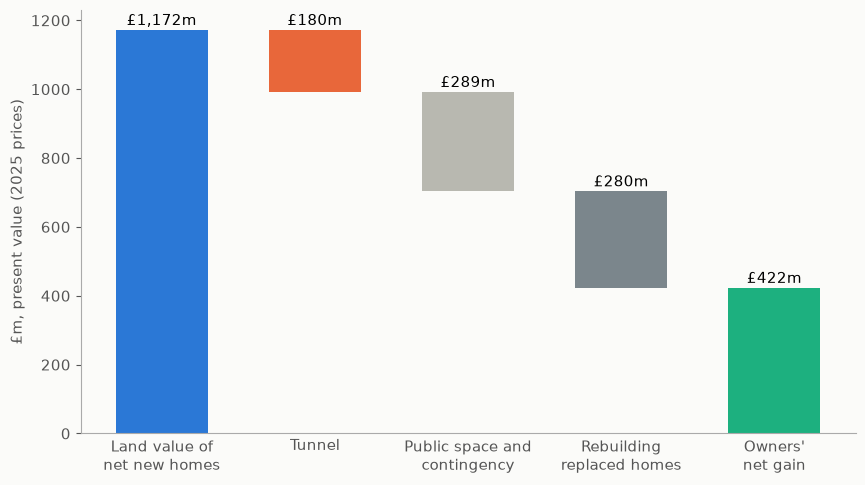

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5.5))
steps = [
    ("Land value of\nnet new homes", 0, pv["land"], COLOURS["southwark"]),
    ("Tunnel", pv["land"] - tunnel, tunnel, COLOURS["tunnel"]),
    ("Public space and\ncontingency", pv["land"] - pv["reserve"], pv["reserve"] - tunnel, COLOURS["rest"]),
    ("Rebuilding\nreplaced homes", pv["owners"], pv["rebuild"], COLOURS["jubilee"]),
    ("Owners'\nnet gain", 0, pv["owners"], COLOURS["other"]),
]
for i, (name, bottom, height, colour) in enumerate(steps):
    ax.bar(i, height, bottom=bottom, color=colour, width=0.6)
    ax.text(i, bottom + height + 15, f"£{height:,.0f}m", ha="center", fontsize=11)
ax.set_xticks(range(len(steps)), [s[0] for s in steps])
ax.tick_params(axis="x", length=0)
ax.set_ylabel(f"£m, present value ({PRICE_YEAR} prices)")
fig.savefig(FIGURES / "value_split.png")

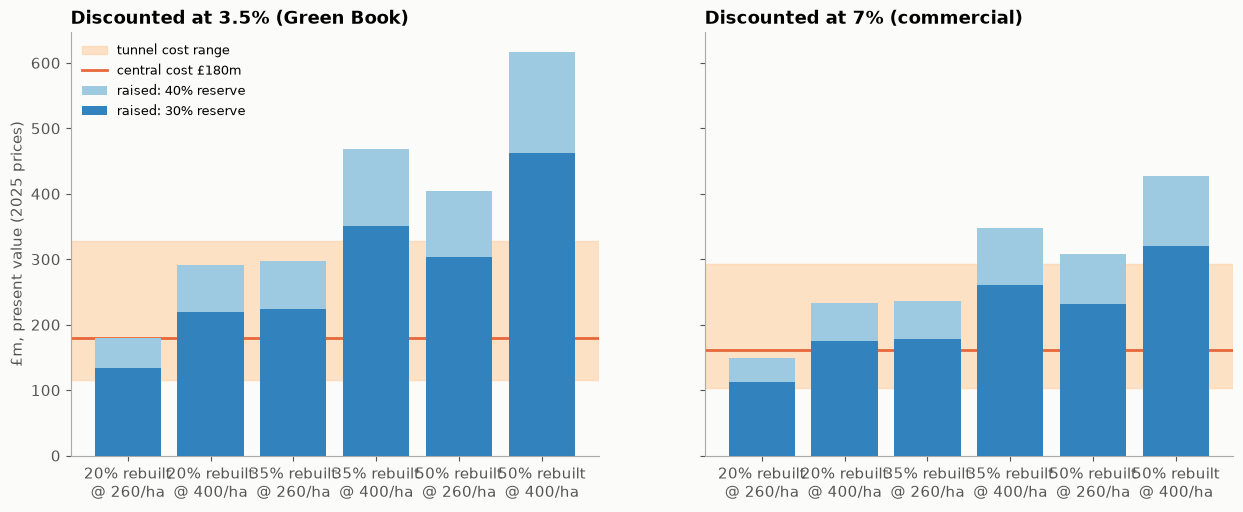

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
labelled = central.assign(label=[f"{s:.0%} rebuilt\n@ {t}/ha" for s, t in zip(central.share, central.target)])
for ax, rate in zip(axes, RATES):
    wide = labelled.pivot_table(index="label", columns="reserve_share", values=f"reserve PV {rate}", sort=False)
    c = pv_cost[rate]
    ax.axhspan(c["low"], c["high"], color="#fdd0a2", alpha=0.6, label="tunnel cost range")
    ax.axhline(c["central"], color=COLOURS["tunnel"], lw=2, label=f"central cost £{c['central']:.0f}m")
    x = np.arange(len(wide))
    ax.bar(x, wide[0.4], color="#9ecae1", label="raised: 40% reserve", zorder=3)
    ax.bar(x, wide[0.3], color="#3182bd", label="raised: 30% reserve", zorder=3)
    ax.set_xticks(x, wide.index)
    ax.set_title(f"Discounted at {rate}", fontsize=13)
axes[0].set_ylabel(f"£m, present value ({PRICE_YEAR} prices)")
axes[0].legend(loc="upper left", fontsize=9)
fig.savefig(FIGURES / "funding_vs_cost.png")